<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №4
## по курсу «Технологии машинного обучения»

### Тема: Линейные модели, SVM и деревья решений

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Описание задания

**Цель работы:** изучение линейных моделей, SVM и деревьев решений.

**Задание:**
1. Выбрать набор данных для решения задачи классификации или регрессии.
2. В случае необходимости провести удаление или заполнение пропусков и кодирование категориальных признаков.
3. С использованием метода train_test_split разделить выборку на обучающую и тестовую.
4. Обучить модели: одну из линейных моделей (для классификации — логистическую регрессию), SVM, дерево решений.
5. Оценить качество моделей с помощью двух подходящих для задачи метрик. Сравнить качество полученных моделей.
6. Построить график, показывающий важность признаков в дереве решений.
7. Визуализировать дерево решений или вывести правила дерева решений в текстовом виде.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import warnings

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=RuntimeWarning)  # лишние предупреждения numpy на macOS

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"


## 2. Набор данных

Используется финансовый датасет **Loan Prediction Problem Dataset** (заявки на кредит, https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset), как в ЛР2 и ЛР3. Решается задача **бинарной классификации**: предсказать `Loan_Status` — одобрят ли кредит (1) или откажут (0).


In [2]:
df = pd.read_csv("loan_prediction.csv")
print("Размер:", df.shape)
print(df["Loan_Status"].value_counts())
df.head()


Размер: (614, 13)
Loan_Status
Y    422
N    192
Name: count, dtype: int64


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Предобработка данных

Пропуски заполняем медианой и модой, категориальные признаки кодируем (так же, как в ЛР2).


In [3]:
data = df.drop(columns=["Loan_ID"])

data[["LoanAmount"]] = SimpleImputer(strategy="median").fit_transform(data[["LoanAmount"]])
mode_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Loan_Amount_Term", "Credit_History"]
data[mode_cols] = SimpleImputer(strategy="most_frequent").fit_transform(data[mode_cols])

for col in ["Gender", "Married", "Education", "Self_Employed", "Loan_Status"]:
    data[col] = LabelEncoder().fit_transform(data[col])
data["Dependents"] = OrdinalEncoder(categories=[["0", "1", "2", "3+"]]).fit_transform(data[["Dependents"]])
data = pd.get_dummies(data, columns=["Property_Area"], prefix="Area", dtype=int)
data = data.astype(float)

print("Пропусков:", data.isnull().sum().sum())
data.head()


Пропусков: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,1.0,0.0,0.0,0.0,0.0,5849.0,0.0,128.0,360.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,1.0,0.0,0.0,4583.0,1508.0,128.0,360.0,1.0,0.0,1.0,0.0,0.0
2,1.0,1.0,0.0,0.0,1.0,3000.0,0.0,66.0,360.0,1.0,1.0,0.0,0.0,1.0
3,1.0,1.0,0.0,1.0,0.0,2583.0,2358.0,120.0,360.0,1.0,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,6000.0,0.0,141.0,360.0,1.0,1.0,0.0,0.0,1.0


## 4. Разделение на обучающую и тестовую выборки


In [4]:
X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)
print("Обучающая выборка:", X_train.shape, " Тестовая выборка:", X_test.shape)

# масштабирование нужно для логистической регрессии и SVM, дереву оно не нужно
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)


Обучающая выборка: (460, 13)  Тестовая выборка: (154, 13)


## 5. Обучение моделей

Качество оцениваем двумя метриками: **accuracy** (доля верных ответов) и **F1-мера** (учитывает precision и recall, важна из-за несбалансированных классов). Дополнительно выводим ROC-AUC.


In [5]:
results = {}

def evaluate(name, model, X_te):
    pred = model.predict(X_te)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_te)[:, 1]
    else:
        score = model.decision_function(X_te)
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    print(name)
    for k, v in results[name].items():
        print(f"  {k:9} {v:.4f}")
    return pred


### 5.1. Логистическая регрессия


In [6]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_sc, y_train)
pred_lr = evaluate("Логистическая регрессия", log_reg, X_test_sc)


Логистическая регрессия
  Accuracy  0.8247
  F1        0.8870
  ROC-AUC   0.7738


In [7]:
# коэффициенты линейной модели: знак показывает, в какую сторону признак влияет на одобрение
coef = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
coef.round(3)


Area_Rural          -0.196
Loan_Amount_Term    -0.150
CoapplicantIncome   -0.140
Education           -0.120
Area_Urban          -0.111
LoanAmount          -0.111
Dependents          -0.039
Self_Employed       -0.031
ApplicantIncome      0.054
Gender               0.063
Married              0.257
Area_Semiurban       0.293
Credit_History       1.238
dtype: float64

### 5.2. Метод опорных векторов (SVM)

Обучим SVM с линейным ядром и с RBF-ядром.


In [8]:
svm_linear = SVC(kernel="linear")
svm_linear.fit(X_train_sc, y_train)
pred_svm_lin = evaluate("SVM (линейное ядро)", svm_linear, X_test_sc)

svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_rbf.fit(X_train_sc, y_train)
pred_svm = evaluate("SVM (RBF-ядро)", svm_rbf, X_test_sc)


SVM (линейное ядро)
  Accuracy  0.8247
  F1        0.8870
  ROC-AUC   0.7695
SVM (RBF-ядро)
  Accuracy  0.8312
  F1        0.8908
  ROC-AUC   0.7557


### 5.3. Дерево решений

Сначала обучим дерево без ограничения глубины, затем ограничим глубину, чтобы дерево не переобучалось и его можно было нарисовать.


In [9]:
tree_full = DecisionTreeClassifier(random_state=1)
tree_full.fit(X_train, y_train)
print("Глубина дерева без ограничений:", tree_full.get_depth(), " листьев:", tree_full.get_n_leaves())
print("Accuracy на обучающей выборке:", round(accuracy_score(y_train, tree_full.predict(X_train)), 4))
pred_tree_full = evaluate("Дерево решений (без ограничений)", tree_full, X_test)


Глубина дерева без ограничений: 16  листьев: 110
Accuracy на обучающей выборке: 1.0
Дерево решений (без ограничений)
  Accuracy  0.7468
  F1        0.8186
  ROC-AUC   0.6963


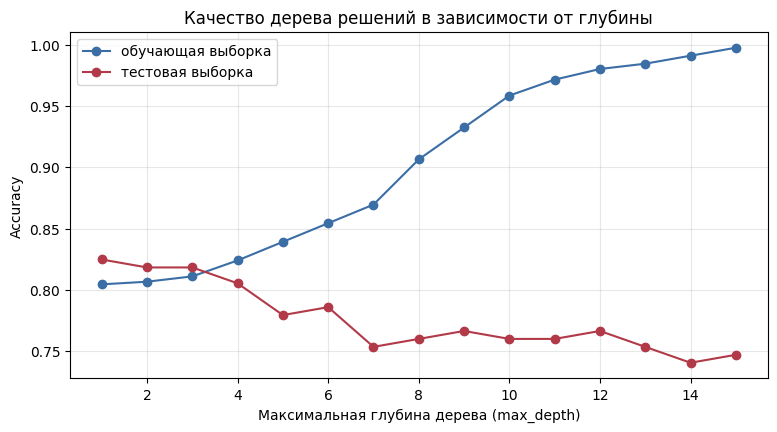

In [10]:
# как глубина дерева влияет на качество
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=1).fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, t.predict(X_train)))
    test_acc.append(accuracy_score(y_test, t.predict(X_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_acc, marker="o", color=BLUE, label="обучающая выборка")
plt.plot(depths, test_acc, marker="o", color=RED, label="тестовая выборка")
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("Accuracy")
plt.title("Качество дерева решений в зависимости от глубины")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [11]:
tree = DecisionTreeClassifier(max_depth=3, random_state=1)
tree.fit(X_train, y_train)
pred_tree = evaluate("Дерево решений (max_depth = 3)", tree, X_test)


Дерево решений (max_depth = 3)
  Accuracy  0.8182
  F1        0.8833
  ROC-AUC   0.7301


## 6. Сравнение качества моделей


In [12]:
compare = pd.DataFrame(results).T.round(4)
compare


,Accuracy,F1,ROC-AUC
Логистическая регрессия,0.8247,0.8870,0.7738
SVM (линейное ядро),0.8247,0.8870,0.7695
SVM (RBF-ядро),0.8312,0.8908,0.7557
Дерево решений (без ограничений),0.7468,0.8186,0.6963
Дерево решений (max_depth = 3),0.8182,0.8833,0.7301


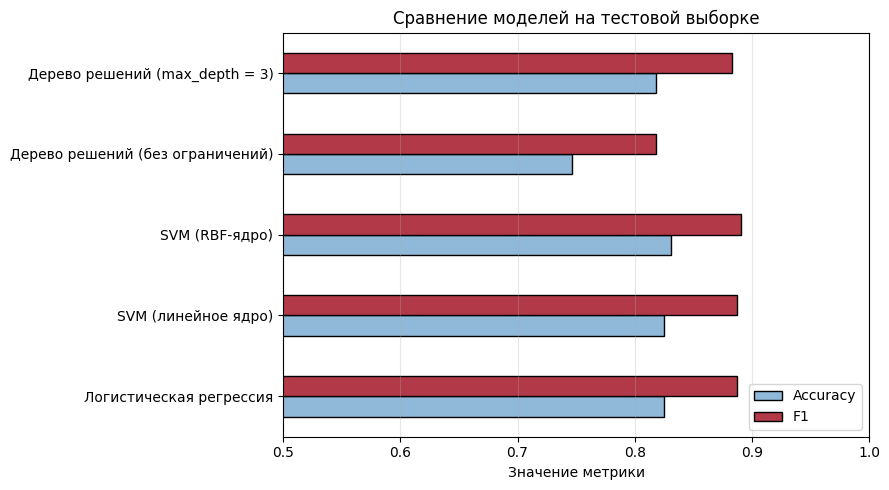

In [13]:
ax = compare[["Accuracy", "F1"]].plot(kind="barh", figsize=(9, 5), color=[BLUE_LIGHT, RED], edgecolor="black")
plt.title("Сравнение моделей на тестовой выборке")
plt.xlabel("Значение метрики")
plt.xlim(0.5, 1)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


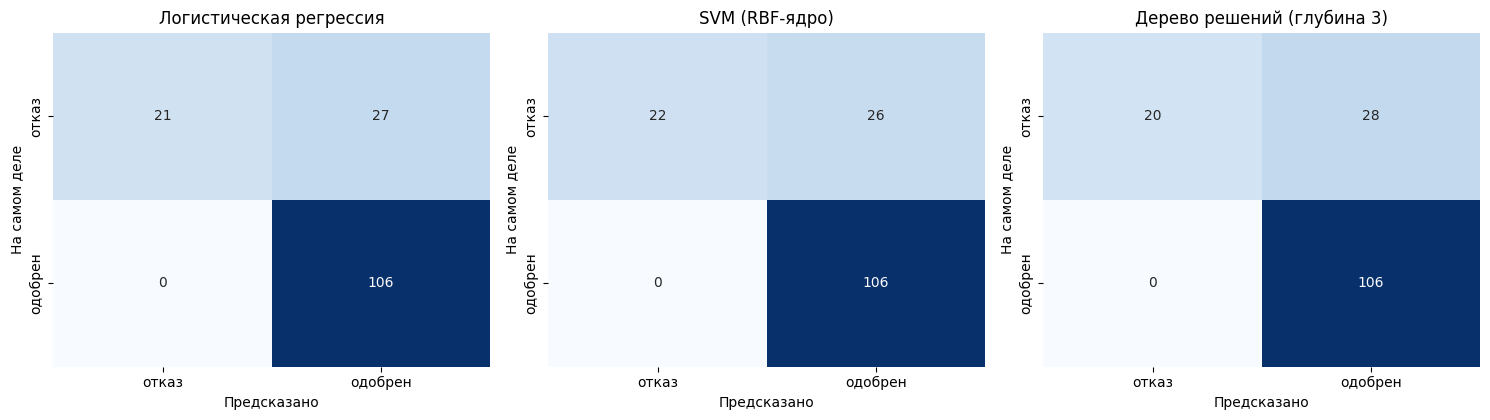

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (title, pred) in zip(axes, [("Логистическая регрессия", pred_lr),
                                     ("SVM (RBF-ядро)", pred_svm),
                                     ("Дерево решений (глубина 3)", pred_tree)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["отказ", "одобрен"], yticklabels=["отказ", "одобрен"])
    ax.set_title(title)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("На самом деле")
plt.tight_layout()
plt.show()


## 7. Важность признаков в дереве решений


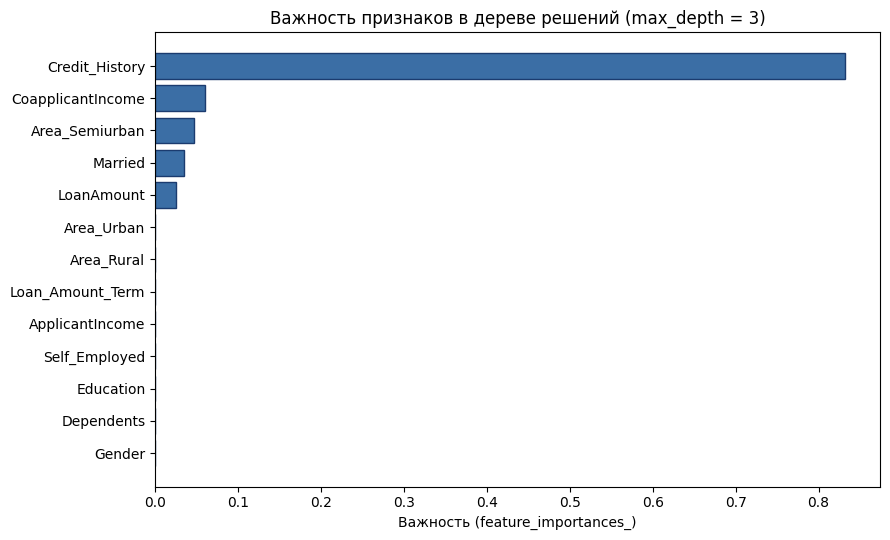

Credit_History       0.8325
CoapplicantIncome    0.0603
Area_Semiurban       0.0472
Married              0.0350
LoanAmount           0.0250
Gender               0.0000
Dependents           0.0000
Education            0.0000
Self_Employed        0.0000
ApplicantIncome      0.0000
Loan_Amount_Term     0.0000
Area_Rural           0.0000
Area_Urban           0.0000
dtype: float64

In [15]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(9, 5.5))
plt.barh(importance.index, importance.values, color=BLUE, edgecolor=BLUE_DARK)
plt.title("Важность признаков в дереве решений (max_depth = 3)")
plt.xlabel("Важность (feature_importances_)")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4)


## 8. Визуализация дерева решений


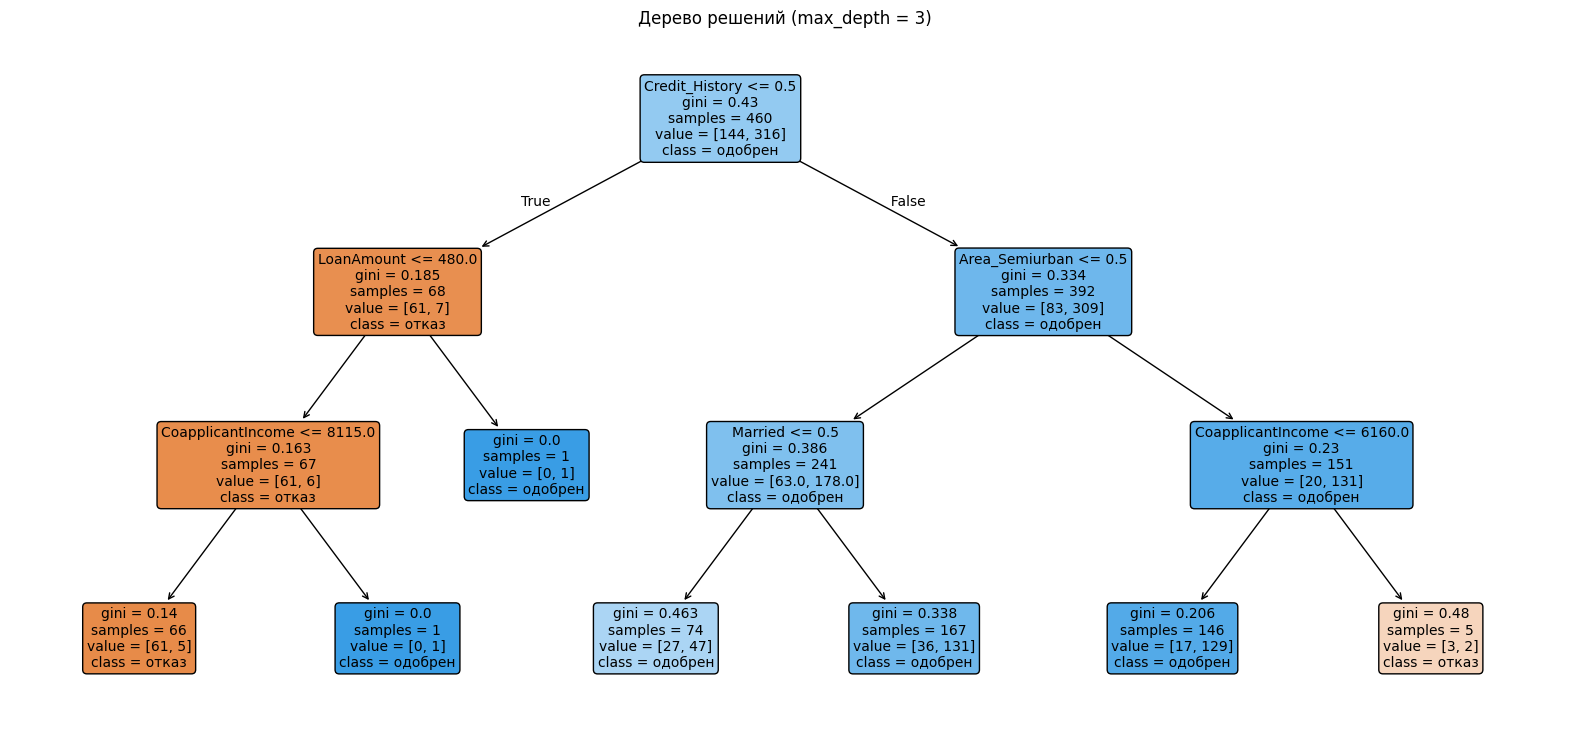

In [16]:
plt.figure(figsize=(20, 9))
plot_tree(tree, feature_names=list(X.columns), class_names=["отказ", "одобрен"],
          filled=True, rounded=True, fontsize=10)
plt.title("Дерево решений (max_depth = 3)")
plt.show()


In [17]:
print(export_text(tree, feature_names=list(X.columns)))


|--- Credit_History <= 0.50
|   |--- LoanAmount <= 480.00
|   |   |--- CoapplicantIncome <= 8115.00
|   |   |   |--- class: 0
|   |   |--- CoapplicantIncome >  8115.00
|   |   |   |--- class: 1
|   |--- LoanAmount >  480.00
|   |   |--- class: 1
|--- Credit_History >  0.50
|   |--- Area_Semiurban <= 0.50
|   |   |--- Married <= 0.50
|   |   |   |--- class: 1
|   |   |--- Married >  0.50
|   |   |   |--- class: 1
|   |--- Area_Semiurban >  0.50
|   |   |--- CoapplicantIncome <= 6160.00
|   |   |   |--- class: 1
|   |   |--- CoapplicantIncome >  6160.00
|   |   |   |--- class: 0



## 9. Выводы

1. Для задачи бинарной классификации (одобрение кредита) использован датасет Loan Prediction: пропуски заполнены, категориальные признаки закодированы, выборка разделена на обучающую и тестовую (75/25, со стратификацией).
2. Обучены логистическая регрессия, SVM (с линейным и RBF-ядром) и дерево решений. Качество оценивалось по accuracy и F1-мере.
3. Лучший результат на тестовой выборке у SVM с RBF-ядром (accuracy 0,831, F1 0,891). Логистическая регрессия и линейный SVM почти не уступают (accuracy 0,825, F1 0,887), а по ROC-AUC логистическая регрессия лучшая (0,774).
4. Дерево решений без ограничения глубины переобучилось: на обучающей выборке accuracy 1,0, на тестовой — 0,747. Ограничение глубины (max_depth = 3) повысило accuracy на тесте до 0,818 и сделало дерево понятным.
5. Самый важный признак в дереве — Credit_History (важность 0,83): клиентам с плохой кредитной историей кредит, как правило, не одобряют. Это же подтверждает самый большой коэффициент логистической регрессии (1,24). Остальные признаки (доход созаёмщика, район, семейное положение, сумма кредита) влияют слабо.
